# alejandro_baquero_lab15 — Medical image recognition (PneumoniaMNIST, chest X-ray)
Transfer learning with MobileNetV2 → accuracy check (> 0.7) → prediction on 4 test images → export `model.tflite` + `labels.txt` for Android Studio.



## 1. Install and import

In [4]:
!pip install -q medmnist
import os, zipfile
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
import medmnist
from medmnist import INFO
print("TensorFlow:", tf.__version__, "| MedMNIST:", medmnist.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0 | MedMNIST: 3.0.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download the dataset (224×224 chest X-rays: normal vs pneumonia)

In [5]:
DATA_FLAG = 'pneumoniamnist'   # other options: 'bloodmnist', 'dermamnist', 'organamnist', ...
IMG_SIZE = 224
info = INFO[DATA_FLAG]
DataClass = getattr(medmnist, info['python_class'])

train = DataClass(split='train', download=True, size=IMG_SIZE)
val   = DataClass(split='val',   download=True, size=IMG_SIZE)
test  = DataClass(split='test',  download=True, size=IMG_SIZE)

class_names = [info['label'][k] for k in sorted(info['label'], key=int)]
NUM_CLASSES = len(class_names)
print("Classes:", class_names)
print("Train:", train.imgs.shape, "Val:", val.imgs.shape, "Test:", test.imgs.shape)

100%|██████████| 214M/214M [00:14<00:00, 15.2MB/s]


Classes: ['normal', 'pneumonia']
Train: (4708, 224, 224) Val: (524, 224, 224) Test: (624, 224, 224)


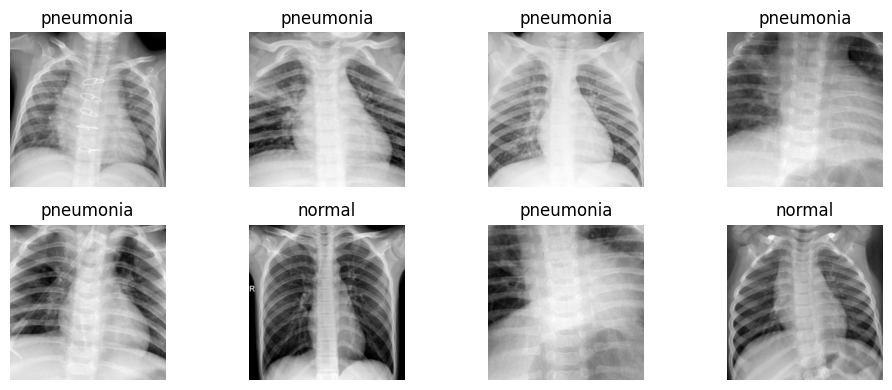

In [6]:
# Quick look at some training images
plt.figure(figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(train.imgs[i], cmap='gray')
    plt.title(class_names[int(train.labels[i][0])])
    plt.axis('off')
plt.tight_layout(); plt.show()

## 3. Input pipeline (pixels kept in 0–255, grayscale → 3 channels)

In [7]:
BATCH = 32

def to_rgb_float(img, label):
    img = tf.cast(img, tf.float32)
    if img.shape.rank == 2:              # grayscale (H, W) -> (H, W, 3)
        img = tf.stack([img, img, img], axis=-1)
    return img, label

def make_ds(d, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((d.imgs, d.labels.flatten().astype('int32')))
    if shuffle:
        ds = ds.shuffle(len(d.imgs), seed=42)
    return ds.map(to_rgb_float, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train, shuffle=True)
val_ds   = make_ds(val)
test_ds  = make_ds(test)

## 4. Model: MobileNetV2 (ImageNet weights) + new classifier head
The `Rescaling` layer is **inside** the model, so the Android app only has to feed raw RGB values (0–255).

In [8]:
base = tf.keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3),
                                         include_top=False, weights='imagenet')
base.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = tf.keras.layers.Rescaling(1./127.5, offset=-1)(inputs)   # 0..255 -> -1..1
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
model = tf.keras.Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5. Train

In [9]:
history = model.fit(train_ds, validation_data=val_ds, epochs=8)

Epoch 1/8
148/148 ━━━━━━━━━━━━━━━━━━━━ 70s 292ms/step - accuracy: 0.8936 - loss: 0.2641 - val_accuracy: 0.9447 - val_loss: 0.1391
Epoch 2/8
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 44ms/step - accuracy: 0.9482 - loss: 0.1299 - val_accuracy: 0.9561 - val_loss: 0.1083
Epoch 3/8
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.9601 - loss: 0.1086 - val_accuracy: 0.9580 - val_loss: 0.0951
Epoch 4/8
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.9633 - loss: 0.0951 - val_accuracy: 0.9580 - val_loss: 0.0887
Epoch 5/8
148/148 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.9658 - loss: 0.0896 - val_accuracy: 0.9637 - val_loss: 0.1032
Epoch 6/8
148/148 ━━━━━━━━━━━━━━━━━━━━ 11s 45ms/step - accuracy: 0.9667 - loss: 0.0820 - val_accuracy: 0.9637 - val_loss: 0.0811
Epoch 7/8
148/148 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - accuracy: 0.9709 - loss: 0.0777 - val_accuracy: 0.9676 - val_loss: 0.0798
Epoch 8/8
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 44ms/step - accuracy: 0.9726 - loss: 0.0722 - val_accuracy:

## 6. Fine-tune the last layers of the base

In [10]:
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_ft = model.fit(train_ds, validation_data=val_ds, epochs=5)

Epoch 1/5
148/148 ━━━━━━━━━━━━━━━━━━━━ 42s 151ms/step - accuracy: 0.9267 - loss: 0.1905 - val_accuracy: 0.9656 - val_loss: 0.0805
Epoch 2/5
148/148 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.9520 - loss: 0.1174 - val_accuracy: 0.9676 - val_loss: 0.0778
Epoch 3/5
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.9664 - loss: 0.0894 - val_accuracy: 0.9714 - val_loss: 0.0738
Epoch 4/5
148/148 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.9783 - loss: 0.0618 - val_accuracy: 0.9752 - val_loss: 0.0723
Epoch 5/5
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 50ms/step - accuracy: 0.9805 - loss: 0.0491 - val_accuracy: 0.9771 - val_loss: 0.0667


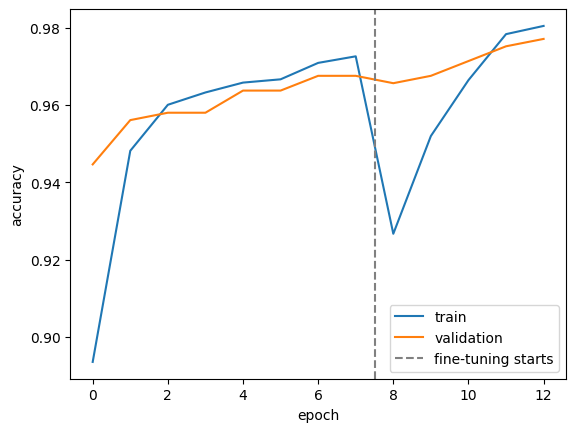

In [11]:
acc = history.history['accuracy'] + history_ft.history['accuracy']
val_acc = history.history['val_accuracy'] + history_ft.history['val_accuracy']
plt.plot(acc, label='train'); plt.plot(val_acc, label='validation')
plt.axvline(len(history.history['accuracy']) - 0.5, ls='--', c='gray', label='fine-tuning starts')
plt.xlabel('epoch'); plt.ylabel('accuracy'); plt.legend(); plt.show()

## 7. Accuracy on the test set

In [12]:
loss, acc = model.evaluate(test_ds)
print(f'Test loss: {loss:.4f}, Test accuracy: {acc:.4f}')

20/20 ━━━━━━━━━━━━━━━━━━━━ 16s 848ms/step - accuracy: 0.8750 - loss: 0.4644
Test loss: 0.4644, Test accuracy: 0.8750


## 8. Save 4 test images (2 per class) and predict them

test_images/test1.png: true = normal | Prediction: pneumonia (1.0000)
test_images/test2.png: true = normal | Prediction: normal (0.9996)
test_images/test3.png: true = pneumonia | Prediction: pneumonia (0.9996)
test_images/test4.png: true = pneumonia | Prediction: pneumonia (1.0000)


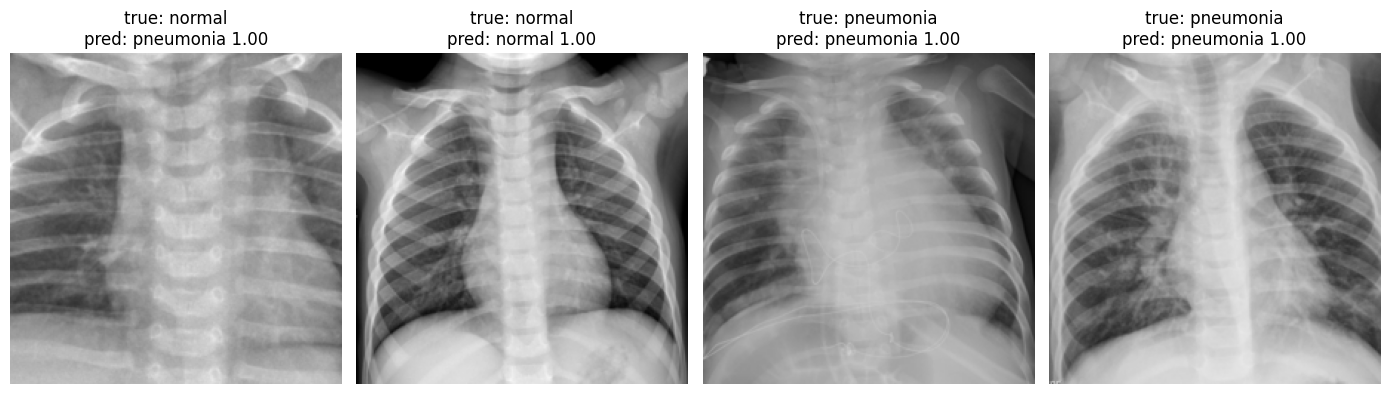

In [13]:
os.makedirs('test_images', exist_ok=True)
y_test = test.labels.flatten()
picks = []
for c in range(NUM_CLASSES):
    picks += list(np.where(y_test == c)[0][:max(1, 4 // NUM_CLASSES)])
picks = picks[:4]

paths = []
for i, k in enumerate(picks):
    p = f'test_images/test{i+1}.png'
    Image.fromarray(test.imgs[k]).save(p)
    paths.append((p, class_names[y_test[k]]))

def load_image(path):
    img = Image.open(path).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
    return np.array(img, dtype=np.float32)

plt.figure(figsize=(14, 4))
for i, (p, true_label) in enumerate(paths):
    img_array = np.expand_dims(load_image(p), axis=0)
    predictions = model.predict(img_array, verbose=0)
    predicted_label = np.argmax(predictions, axis=1)[0]
    print(f'{p}: true = {true_label} | Prediction: {class_names[predicted_label]} '
          f'({predictions[0][predicted_label]:.4f})')
    plt.subplot(1, 4, i + 1)
    plt.imshow(load_image(p).astype('uint8'))
    plt.title(f'true: {true_label}\npred: {class_names[predicted_label]} '
              f'{predictions[0][predicted_label]:.2f}')
    plt.axis('off')
plt.tight_layout(); plt.show()

## 9. Convert to TensorFlow Lite + labels file

In [14]:
model.export('saved_model')
converter = tf.lite.TFLiteConverter.from_saved_model('saved_model')
tflite_model = converter.convert()
with open('model.tflite', 'wb') as f:
    f.write(tflite_model)
with open('labels.txt', 'w') as f:
    f.write('\n'.join(class_names))
print('model.tflite size: %.1f MB' % (len(tflite_model) / 1e6))

Saved artifact at 'saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  139882271445392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139882271445200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139882271446160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139882271446352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139882271445968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139882271446544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139882271445584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139882271447312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139882271445776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139882271444048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139882271446928

## 10. Check that the .tflite model gives the same predictions (This was just a verification for the android studio results, because if the android studio gave something different then it all would be wrong)

In [15]:
interp = tf.lite.Interpreter(model_path='model.tflite')
interp.allocate_tensors()
inp = interp.get_input_details()[0]
out = interp.get_output_details()[0]
print('Input:', inp['shape'], inp['dtype'], '| Output:', out['shape'])

for p, true_label in paths:
    interp.set_tensor(inp['index'], np.expand_dims(load_image(p), 0))
    interp.invoke()
    probs = interp.get_tensor(out['index'])[0]
    print(p, '->', {class_names[i]: round(float(probs[i]), 4) for i in range(NUM_CLASSES)})

Input: [  1 224 224   3] <class 'numpy.float32'> | Output: [1 2]
test_images/test1.png -> {'normal': 0.0, 'pneumonia': 1.0}
test_images/test2.png -> {'normal': 0.9996, 'pneumonia': 0.0004}
test_images/test3.png -> {'normal': 0.0004, 'pneumonia': 0.9996}
test_images/test4.png -> {'normal': 0.0, 'pneumonia': 1.0}


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## 11. Download everything needed for Android Studio

In [16]:
with zipfile.ZipFile('lab15_android_assets.zip', 'w') as z:
    z.write('model.tflite'); z.write('labels.txt')
    for p, _ in paths:
        z.write(p, arcname=os.path.basename(p))

from google.colab import files
files.download('lab15_android_assets.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>